In [4]:
import sys, json, joblib
from pathlib import Path

ROOT_DIR = Path(r"c:\Project\napasloka\napasloka")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import pandas as pd

summary_path = ROOT_DIR / "artifacts" / "summary_metrics.csv"
df_summary = pd.read_csv(summary_path)

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Agregasi rata-rata waktu per skenario dan algoritma
agg_time = df_summary.groupby(["scenario", "algorithm"])[["training_time_seconds", "prediction_time_seconds"]].mean().reset_index()
agg_time["prediction_time_seconds"] = agg_time["prediction_time_seconds"] * 1000
agg_time

,scenario,algorithm,training_time_seconds,prediction_time_seconds
0,scenario_1,lightgbm,5.113107,21.184937
1,scenario_1,xgboost,2.325143,6.250333
2,scenario_2,lightgbm,7.149909,22.623270
3,scenario_2,xgboost,10.902697,6.121213


✓ Diagram komparasi waktu berhasil disimpan di: komparasi_waktu_komputasi.png


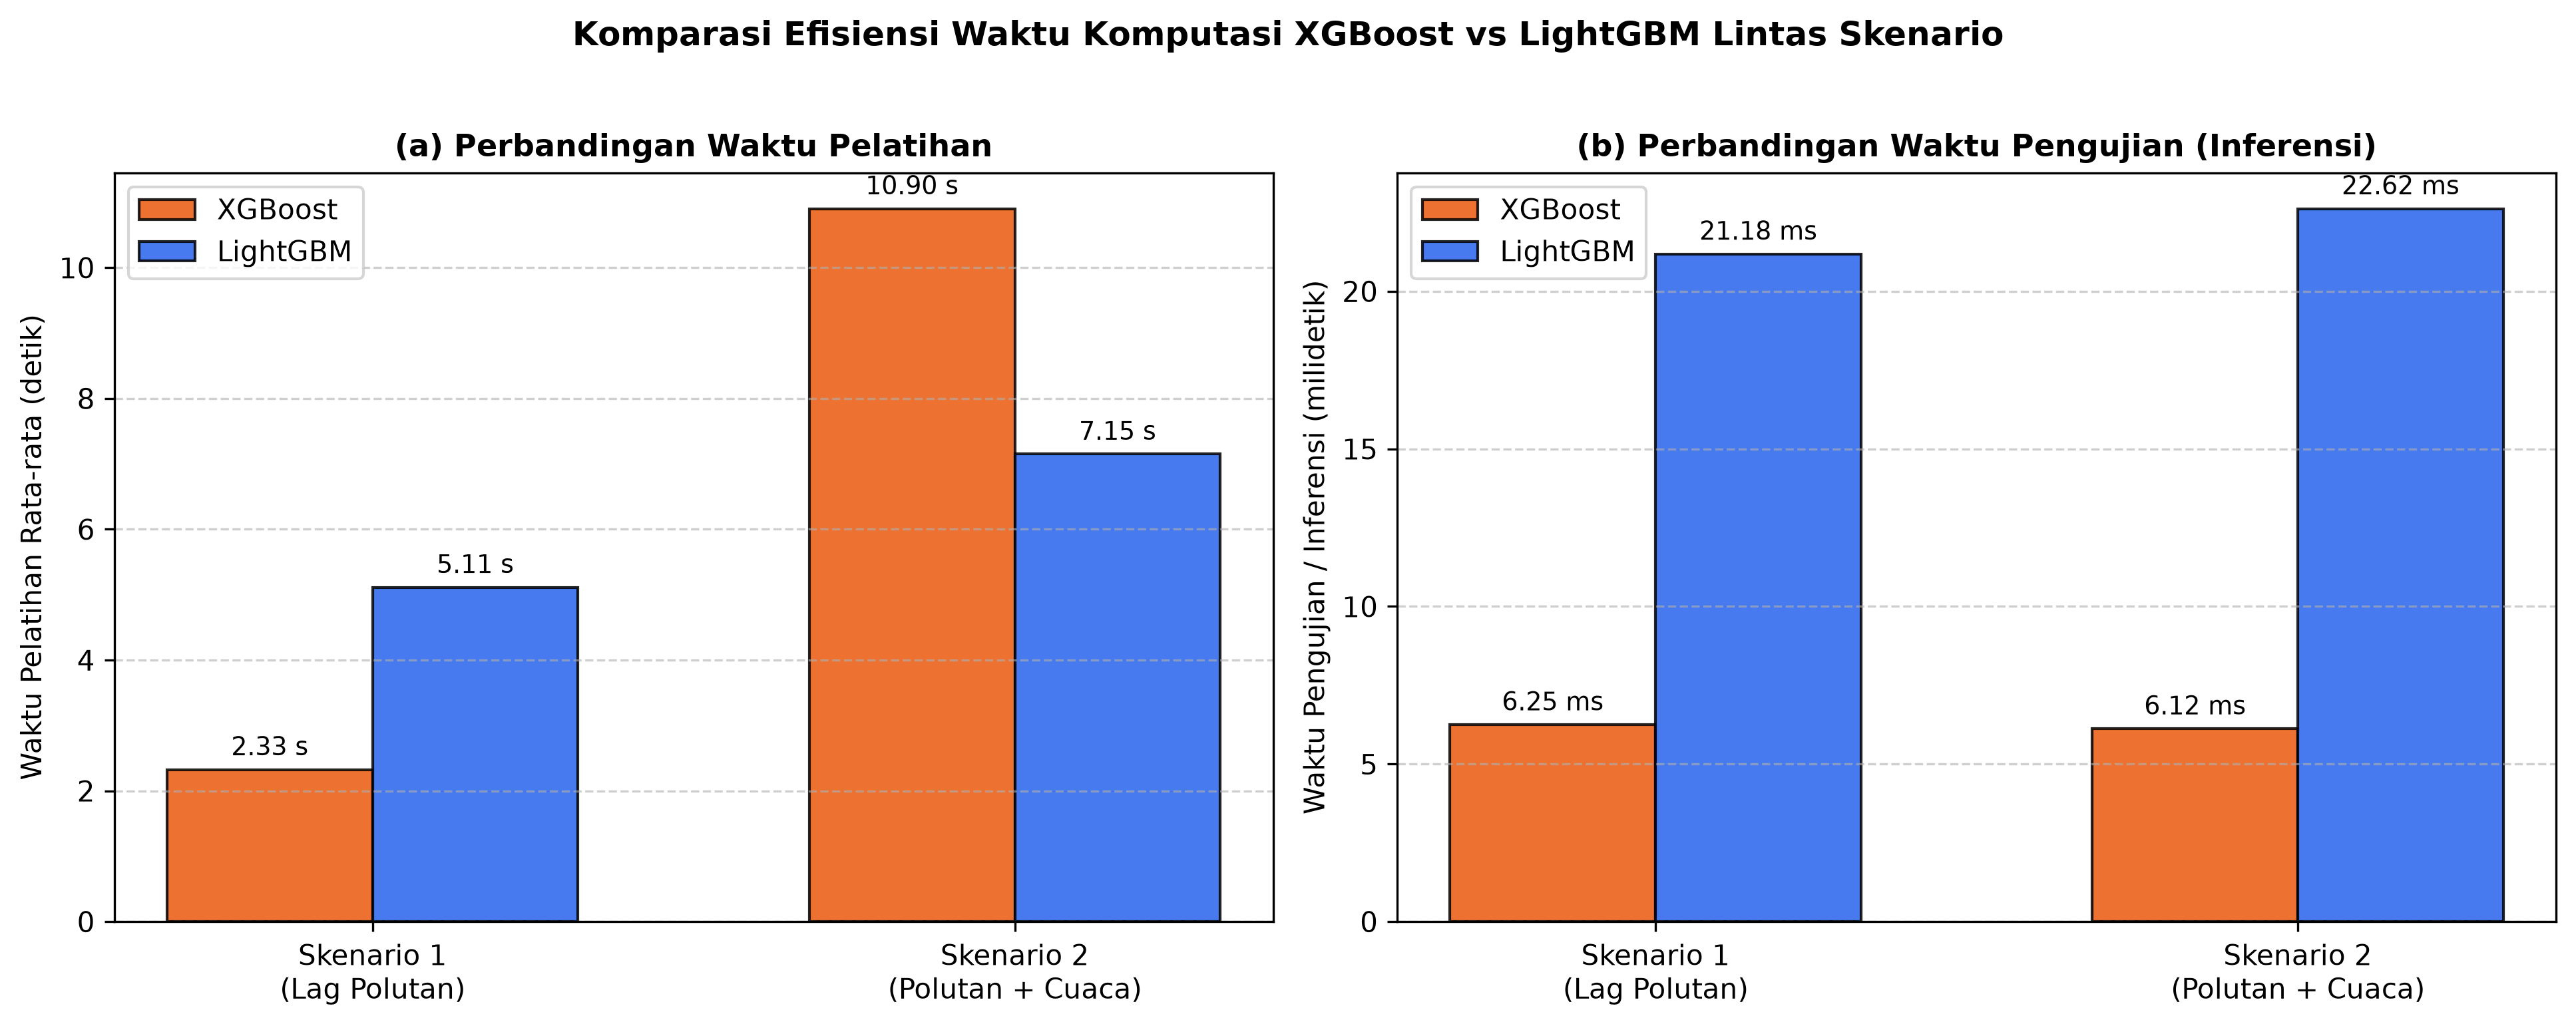

In [8]:
# Setup visualisasi 2 panel berdampingan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
scenarios = ["Skenario 1\n(Lag Polutan)", "Skenario 2\n(Polutan + Cuaca)"]
x = np.arange(len(scenarios))
width = 0.32
xgb_train = [
    agg_time[(agg_time["scenario"] == "scenario_1") & (agg_time["algorithm"] == "xgboost")]["training_time_seconds"].values[0],
    agg_time[(agg_time["scenario"] == "scenario_2") & (agg_time["algorithm"] == "xgboost")]["training_time_seconds"].values[0],
]
lgb_train = [
    agg_time[(agg_time["scenario"] == "scenario_1") & (agg_time["algorithm"] == "lightgbm")]["training_time_seconds"].values[0],
    agg_time[(agg_time["scenario"] == "scenario_2") & (agg_time["algorithm"] == "lightgbm")]["training_time_seconds"].values[0],
]

# Panel 1: Waktu Pelatihan
rects1 = ax1.bar(
    x - width / 2,
    xgb_train,
    width,
    label="XGBoost",
    color="#ea580c",
    edgecolor="black",
    alpha=0.85,
)
rects2 = ax1.bar(
    x + width / 2,
    lgb_train,
    width,
    label="LightGBM",
    color="#2563eb",
    edgecolor="black",
    alpha=0.85,
)
ax1.set_ylabel("Waktu Pelatihan Rata-rata (detik)", fontsize=10)
ax1.set_title(
    "(a) Perbandingan Waktu Pelatihan", fontsize=11, fontweight="bold"
)
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios, fontsize=10)
ax1.legend(loc="upper left")
ax1.grid(axis="y", linestyle="--", alpha=0.6)
ax1.bar_label(rects1, fmt="%.2f s", padding=3, fontsize=9)
ax1.bar_label(rects2, fmt="%.2f s", padding=3, fontsize=9)

# Data Waktu Pengujian (Konversi ke milidetik / ms)
xgb_test = [
    agg_time[(agg_time["scenario"] == "scenario_1") & (agg_time["algorithm"] == "xgboost")]["prediction_time_seconds"].values[0],
    agg_time[(agg_time["scenario"] == "scenario_2") & (agg_time["algorithm"] == "xgboost")]["prediction_time_seconds"].values[0],
]
lgb_test = [
    agg_time[(agg_time["scenario"] == "scenario_1") & (agg_time["algorithm"] == "lightgbm")]["prediction_time_seconds"].values[0],
    agg_time[(agg_time["scenario"] == "scenario_2") & (agg_time["algorithm"] == "lightgbm")]["prediction_time_seconds"].values[0],
]
# Panel 2: Waktu Pengujian
rects3 = ax2.bar(
    x - width / 2,
    xgb_test,
    width,
    label="XGBoost",
    color="#ea580c",
    edgecolor="black",
    alpha=0.85,
)
rects4 = ax2.bar(
    x + width / 2,
    lgb_test,
    width,
    label="LightGBM",
    color="#2563eb",
    edgecolor="black",
    alpha=0.85,
)
ax2.set_ylabel("Waktu Pengujian / Inferensi (milidetik)", fontsize=10)
ax2.set_title(
    "(b) Perbandingan Waktu Pengujian (Inferensi)",
    fontsize=11,
    fontweight="bold",
)
ax2.set_xticks(x)
ax2.set_xticklabels(scenarios, fontsize=10)
ax2.legend(loc="upper left")
ax2.grid(axis="y", linestyle="--", alpha=0.6)
ax2.bar_label(rects3, fmt="%.2f ms", padding=3, fontsize=9)
ax2.bar_label(rects4, fmt="%.2f ms", padding=3, fontsize=9)
plt.suptitle(
    "Komparasi Efisiensi Waktu Komputasi XGBoost vs LightGBM Lintas Skenario",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
output_time_img = (
    ROOT_DIR / "artifacts" / "komparasi_waktu_komputasi.png"
)
plt.savefig(output_time_img, dpi=300, bbox_inches="tight")
print(f"✓ Diagram komparasi waktu berhasil disimpan di: {output_time_img.name}")
plt.show()